In [2]:
import os
from google.colab import drive

# Unmount if already mounted (might not always work cleanly)
if os.path.isdir('/content/drive'):
  try:
    drive.flush_and_unmount()
  except ValueError:
    pass # Ignore if not mounted

# Ensure the mount point is empty
if os.path.exists('/content/drive') and os.path.isdir('/content/drive'):
  for item in os.listdir('/content/drive'):
    item_path = os.path.join('/content/drive', item)
    if os.path.isfile(item_path) or os.path.islink(item_path):
      os.remove(item_path)
    elif os.path.isdir(item_path):
      import shutil
      shutil.rmtree(item_path)

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [5]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/credit-risk"

# Check the folder structure exists
for folder in ["data/raw", "data/processed", "src", "models", "notebooks", "reports/figures"]:
    path = os.path.join(PROJECT_ROOT, folder)
    status = "✅" if os.path.isdir(path) else "❌ MISSING"
    print(f"{status}  {folder}")

✅  data/raw
✅  data/processed
✅  src
✅  models
✅  notebooks
✅  reports/figures


In [6]:
%%writefile /content/drive/MyDrive/credit-risk/src/features.py

import pandas as pd
import numpy as np

# ── 1. CLEAN DATA ────────────────────────────────────────────────────────────
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """
    Fix impossible values and cap outliers.
    Rule: we cap, not delete — dropping rows loses real borrower signal.
    """
    df = df.copy()

    # RevolvingUtilization is a ratio (0–1). Anything above 1 is a data error.
    df["RevolvingUtilizationOfUnsecuredLines"] = df[
        "RevolvingUtilizationOfUnsecuredLines"
    ].clip(upper=1.0)

    # DebtRatio and MonthlyIncome have extreme right tails — cap at 99th pct.
    for col in ["DebtRatio", "MonthlyIncome"]:
        cap = df[col].quantile(0.99)
        df[col] = df[col].clip(upper=cap)

    # Age of 0 is impossible. Replace with NaN then fill with median.
    df["age"] = df["age"].replace(0, np.nan)
    df["age"] = df["age"].fillna(df["age"].median())

    return df


# ── 2. IMPUTE MISSING VALUES ─────────────────────────────────────────────────
def impute_missing(df: pd.DataFrame) -> pd.DataFrame:
    """
    Impute before engineering so downstream features are never built on NaNs.
    Key: create the missingness FLAG before filling — the flag is itself a feature.
    """
    df = df.copy()

    # income_missing: the fact that income is missing may predict default.
    # Create this flag BEFORE imputing, otherwise you lose the signal.
    df["income_missing"] = df["MonthlyIncome"].isna().astype(int)

    # Smarter imputation: median income grouped by age bracket.
    # A 25-year-old and a 55-year-old have very different income distributions.
    df["age_bracket"] = pd.cut(
        df["age"],
        bins=[0, 25, 35, 45, 55, 65, 120],
        labels=["<25", "25-35", "35-45", "45-55", "55-65", "65+"]
    )
    group_medians = df.groupby("age_bracket", observed=True)["MonthlyIncome"].transform("median")
    df["MonthlyIncome"] = df["MonthlyIncome"].fillna(group_medians)
    # Fallback: if any age bracket is entirely NaN, use global median
    df["MonthlyIncome"] = df["MonthlyIncome"].fillna(df["MonthlyIncome"].median())

    # NumberOfDependents: global median is fine (no strong age interaction here)
    df["NumberOfDependents"] = df["NumberOfDependents"].fillna(
        df["NumberOfDependents"].median()
    )

    # Drop the helper column — it was only needed for grouped imputation
    df = df.drop(columns=["age_bracket"])

    return df


# ── 3. ENGINEER FEATURES ─────────────────────────────────────────────────────
def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Create new columns that encode domain knowledge.
    Every feature here has a business reason — not just math.
    """
    df = df.copy()

    # DebtToIncomeRatio: the single most important metric in credit underwriting.
    # +1 avoids division by zero for zero-income rows.
    df["DebtToIncomeRatio"] = df["DebtRatio"] / (df["MonthlyIncome"] + 1)

    # IncomePerDependent: financial stress — how much income supports each dependent.
    df["IncomePerDependent"] = df["MonthlyIncome"] / (df["NumberOfDependents"] + 1)

    # TotalLatePayments: combines all three delinquency columns into one risk score.
    late_cols = [
        "NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTime60-89DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate",
    ]
    df["TotalLatePayments"] = df[late_cols].sum(axis=1)

    # LatePaymentRatio: late payments relative to total credit exposure.
    df["LatePaymentRatio"] = df["TotalLatePayments"] / (
        df["NumberOfOpenCreditLinesAndLoans"] + 1
    )

    # UtilizationBin: captures nonlinear risk — 0% and 100% are both risky.
    df["UtilizationBin"] = pd.cut(
        df["RevolvingUtilizationOfUnsecuredLines"],
        bins=[-0.01, 0.01, 0.3, 0.7, 1.01],
        labels=["zero", "low", "medium", "high"]
    ).astype(str)

    # AgeGroup: age has nonlinear risk patterns.
    df["AgeGroup"] = pd.cut(
        df["age"],
        bins=[0, 25, 35, 45, 55, 65, 120],
        labels=["<25", "25-35", "35-45", "45-55", "55-65", "65+"]
    ).astype(str)

    # Log transforms for the logistic regression meta-learner in Phase 6.
    # np.log1p = log(x + 1) — handles zeros cleanly.
    for col in ["MonthlyIncome", "DebtRatio", "RevolvingUtilizationOfUnsecuredLines"]:
        df[f"log_{col}"] = np.log1p(df[col])

    return df


# ── 4. MASTER PIPELINE ───────────────────────────────────────────────────────
def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    The one function every notebook calls.
    Order matters: clean → impute → engineer.
    """
    df = clean_data(df)
    df = impute_missing(df)
    df = engineer_features(df)
    return df

Overwriting /content/drive/MyDrive/credit-risk/src/features.py


In [7]:
import sys
import pandas as pd
import numpy as np

PROJECT_ROOT = "/content/drive/MyDrive/credit-risk"
sys.path.insert(0, f"{PROJECT_ROOT}/src")

from features import build_features

df_raw = pd.read_csv(f"{PROJECT_ROOT}/data/raw/cs-training.csv", index_col=0)

print(f"Raw shape:  {df_raw.shape}")
print(f"\nNull counts before:\n{df_raw.isnull().sum()}")

Raw shape:  (150000, 11)

Null counts before:
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64


In [8]:
df = build_features(df_raw)

print(f"Shape after:  {df.shape}")
print(f"\nNull counts after:\n{df.isnull().sum()}")
print(f"\nTotal nulls remaining: {df.isnull().sum().sum()}")

Shape after:  (150000, 21)

Null counts after:
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                               0
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                          0
income_missing                              0
DebtToIncomeRatio                           0
IncomePerDependent                          0
TotalLatePayments                           0
LatePaymentRatio                            0
UtilizationBin                              0
AgeGroup                                    0
log_MonthlyIncome                           0
log_DebtRatio                               0
log_RevolvingUtilizationOfUnsecur

In [ ]:
numeric_df = df.select_dtypes(include=[np.number])

inf_counts = numeric_df.isin([np.inf, -np.inf]).sum()
inf_counts = inf_counts[inf_counts > 0]

if len(inf_counts) == 0:
    print("✅ No infinity values found — all ratio features are clean")
else:
    print("⚠️ Infinity values found:")
    print(inf_counts)

✅ No infinity values found — all ratio features are clean


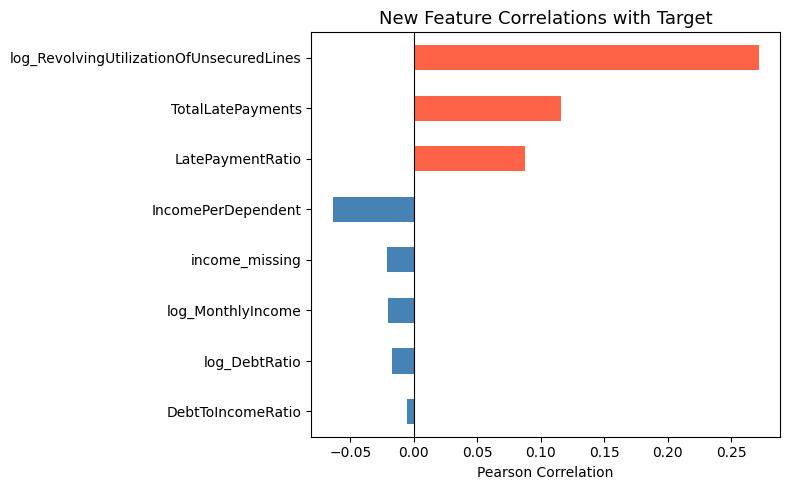

log_RevolvingUtilizationOfUnsecuredLines    0.271462
TotalLatePayments                           0.115513
LatePaymentRatio                            0.087523
IncomePerDependent                         -0.063843
income_missing                             -0.021308
log_MonthlyIncome                          -0.019901
log_DebtRatio                              -0.017360
DebtToIncomeRatio                          -0.004996
Name: SeriousDlqin2yrs, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

target = "SeriousDlqin2yrs"
new_features = [
    "DebtToIncomeRatio", "IncomePerDependent", "TotalLatePayments",
    "LatePaymentRatio", "income_missing", "log_MonthlyIncome",
    "log_DebtRatio", "log_RevolvingUtilizationOfUnsecuredLines"
]

correlations = (
    df[new_features + [target]]
    .corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["tomato" if v > 0 else "steelblue" for v in correlations]
correlations.plot(kind="barh", ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("New Feature Correlations with Target", fontsize=13)
ax.set_xlabel("Pearson Correlation")
plt.tight_layout()
plt.savefig(f"{PROJECT_ROOT}/reports/figures/feature_correlations.png", dpi=150)
plt.show()

print(correlations.sort_values(key=abs, ascending=False))

In [ ]:
save_path = f"{PROJECT_ROOT}/data/processed/df_features.csv"
df.to_csv(save_path, index=False)

print(f"✅ Saved to {save_path}")
print(f"   Rows: {df.shape[0]:,}")
print(f"   Columns: {df.shape[1]}")
print(f"\n   Columns list:\n   {list(df.columns)}")

✅ Saved to /content/drive/MyDrive/credit-risk/data/processed/df_features.csv
   Rows: 150,000
   Columns: 21

   Columns list:
   ['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'income_missing', 'DebtToIncomeRatio', 'IncomePerDependent', 'TotalLatePayments', 'LatePaymentRatio', 'UtilizationBin', 'AgeGroup', 'log_MonthlyIncome', 'log_DebtRatio', 'log_RevolvingUtilizationOfUnsecuredLines']


## Feature Engineering — Summary

Domain knowledge drove every decision in this phase, not automation.

- **TotalLatePayments** aggregates all three delinquency columns into a single
  behavioral risk score — past delinquency is the #1 predictor of future default.
- **log_RevolvingUtilization** (correlation: 0.27) became the strongest engineered
  signal — the log transform exposed the relationship that the raw value obscured.
- **income_missing** captures missingness itself as a risk signal before imputing.
- **DebtToIncomeRatio** and **IncomePerDependent** encode how credit analysts
  actually think — income relative to obligations, not in isolation.

All cleaning, imputation, and engineering live in `src/features.py` as a single
importable pipeline: `build_features(df)`.